# Projet 4 - Classification - domaine RH - Feature Eng. & Modelisation

## Les imports

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from jbtools import describoost
from jbtools import showpearson

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report, roc_auc_score, make_scorer, f1_score, precision_recall_curve
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.model_selection import GridSearchCV
from sklearn.inspection import permutation_importance 
import shap

import time
from datetime import datetime

## Chargement du dataframe (df_expert.parquet from EDA)

In [2]:

df = pd.read_parquet('df_expert.parquet')
describoost(df)


==================== 🚀 DESCRIBOOST : Dataset ====================
Nbre de lignes  : 1470 
Nbre de colonnes: 28 

--- ANALYSE NUMÉRIQUE ---
                                            count     mean      std     min     25%     50%     75%      max skewsc mean/md Minidist  NaNs      Remarque   Suggestion
age                                        1470.0    36.92     9.14    18.0    30.0    36.0    43.0     60.0    0.3     1.0     ▄▄▄▄   0.0             -            -
niveau_education                           1470.0     2.91     1.02     1.0     2.0     3.0     4.0      5.0      0     1.0     ▄▄▄▄   0.0             -            -
distance_domicile_travail                  1470.0     9.19     8.11     1.0     2.0     7.0    14.0     29.0    2.7     1.3     █▄▄_   0.0             -            -
nb_formations_suivies                      1470.0     2.80     1.29     0.0     2.0     3.0     3.0      6.0      0     0.9     ▄▄█▄   0.0             -            -
nombre_participation_pee      

## Pearson

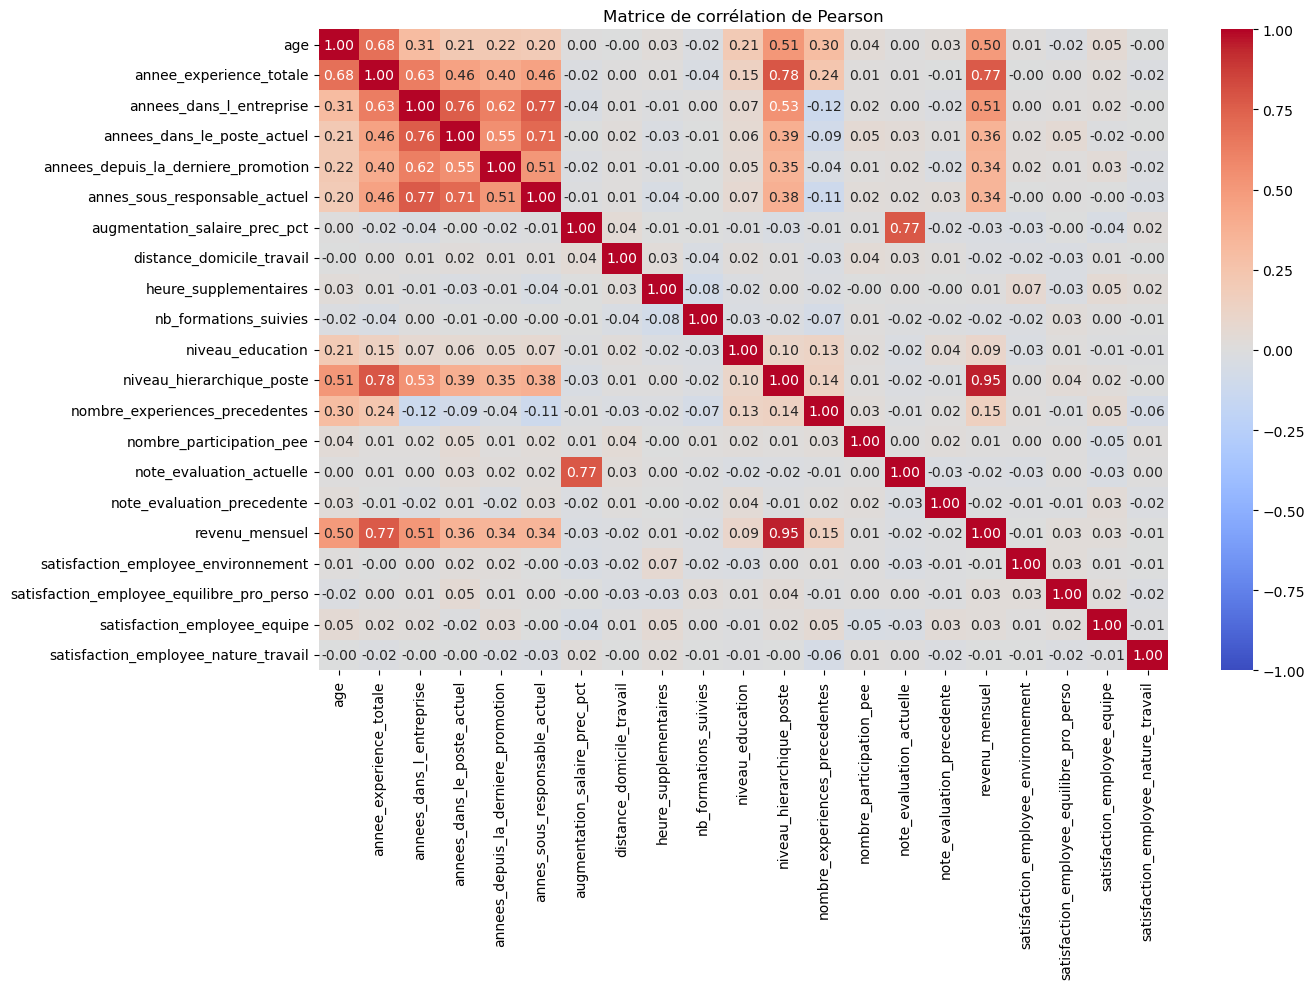

In [3]:
latarget='a_quitte_l_entreprise'

showpearson(df,cols_to_exclude=[latarget])

Revenu_mensuel et niveau_hierarchique_poste très fortement corrélés => 95%  => niveau_hierarchique_poste à dropper  

Revenu_mensuel                  et annee_experience_totale corrélés à 77%          => suppression?  
Note_evaluation_actuelle        et augmentatoion_salaire_prec_pct corrélés à 77%   => suppression?  
Annes_sous_responsable_actuel   et annees_dans_l_entreprise corrélés à 77%   => suppression?  
Annees_dans_le_poste_actuel   et annees_dans_l_entreprise corrélés à 76%   => suppression?  

In [4]:
#df.drop(columns=['niveau_hierarchique_poste'], inplace=True, errors='ignore')     # Drop de la colonne niveau_hierarchique_poste
df.drop(columns=['departement'], inplace=True, errors='ignore')     # Drop de la colonne departement

## Pairplots

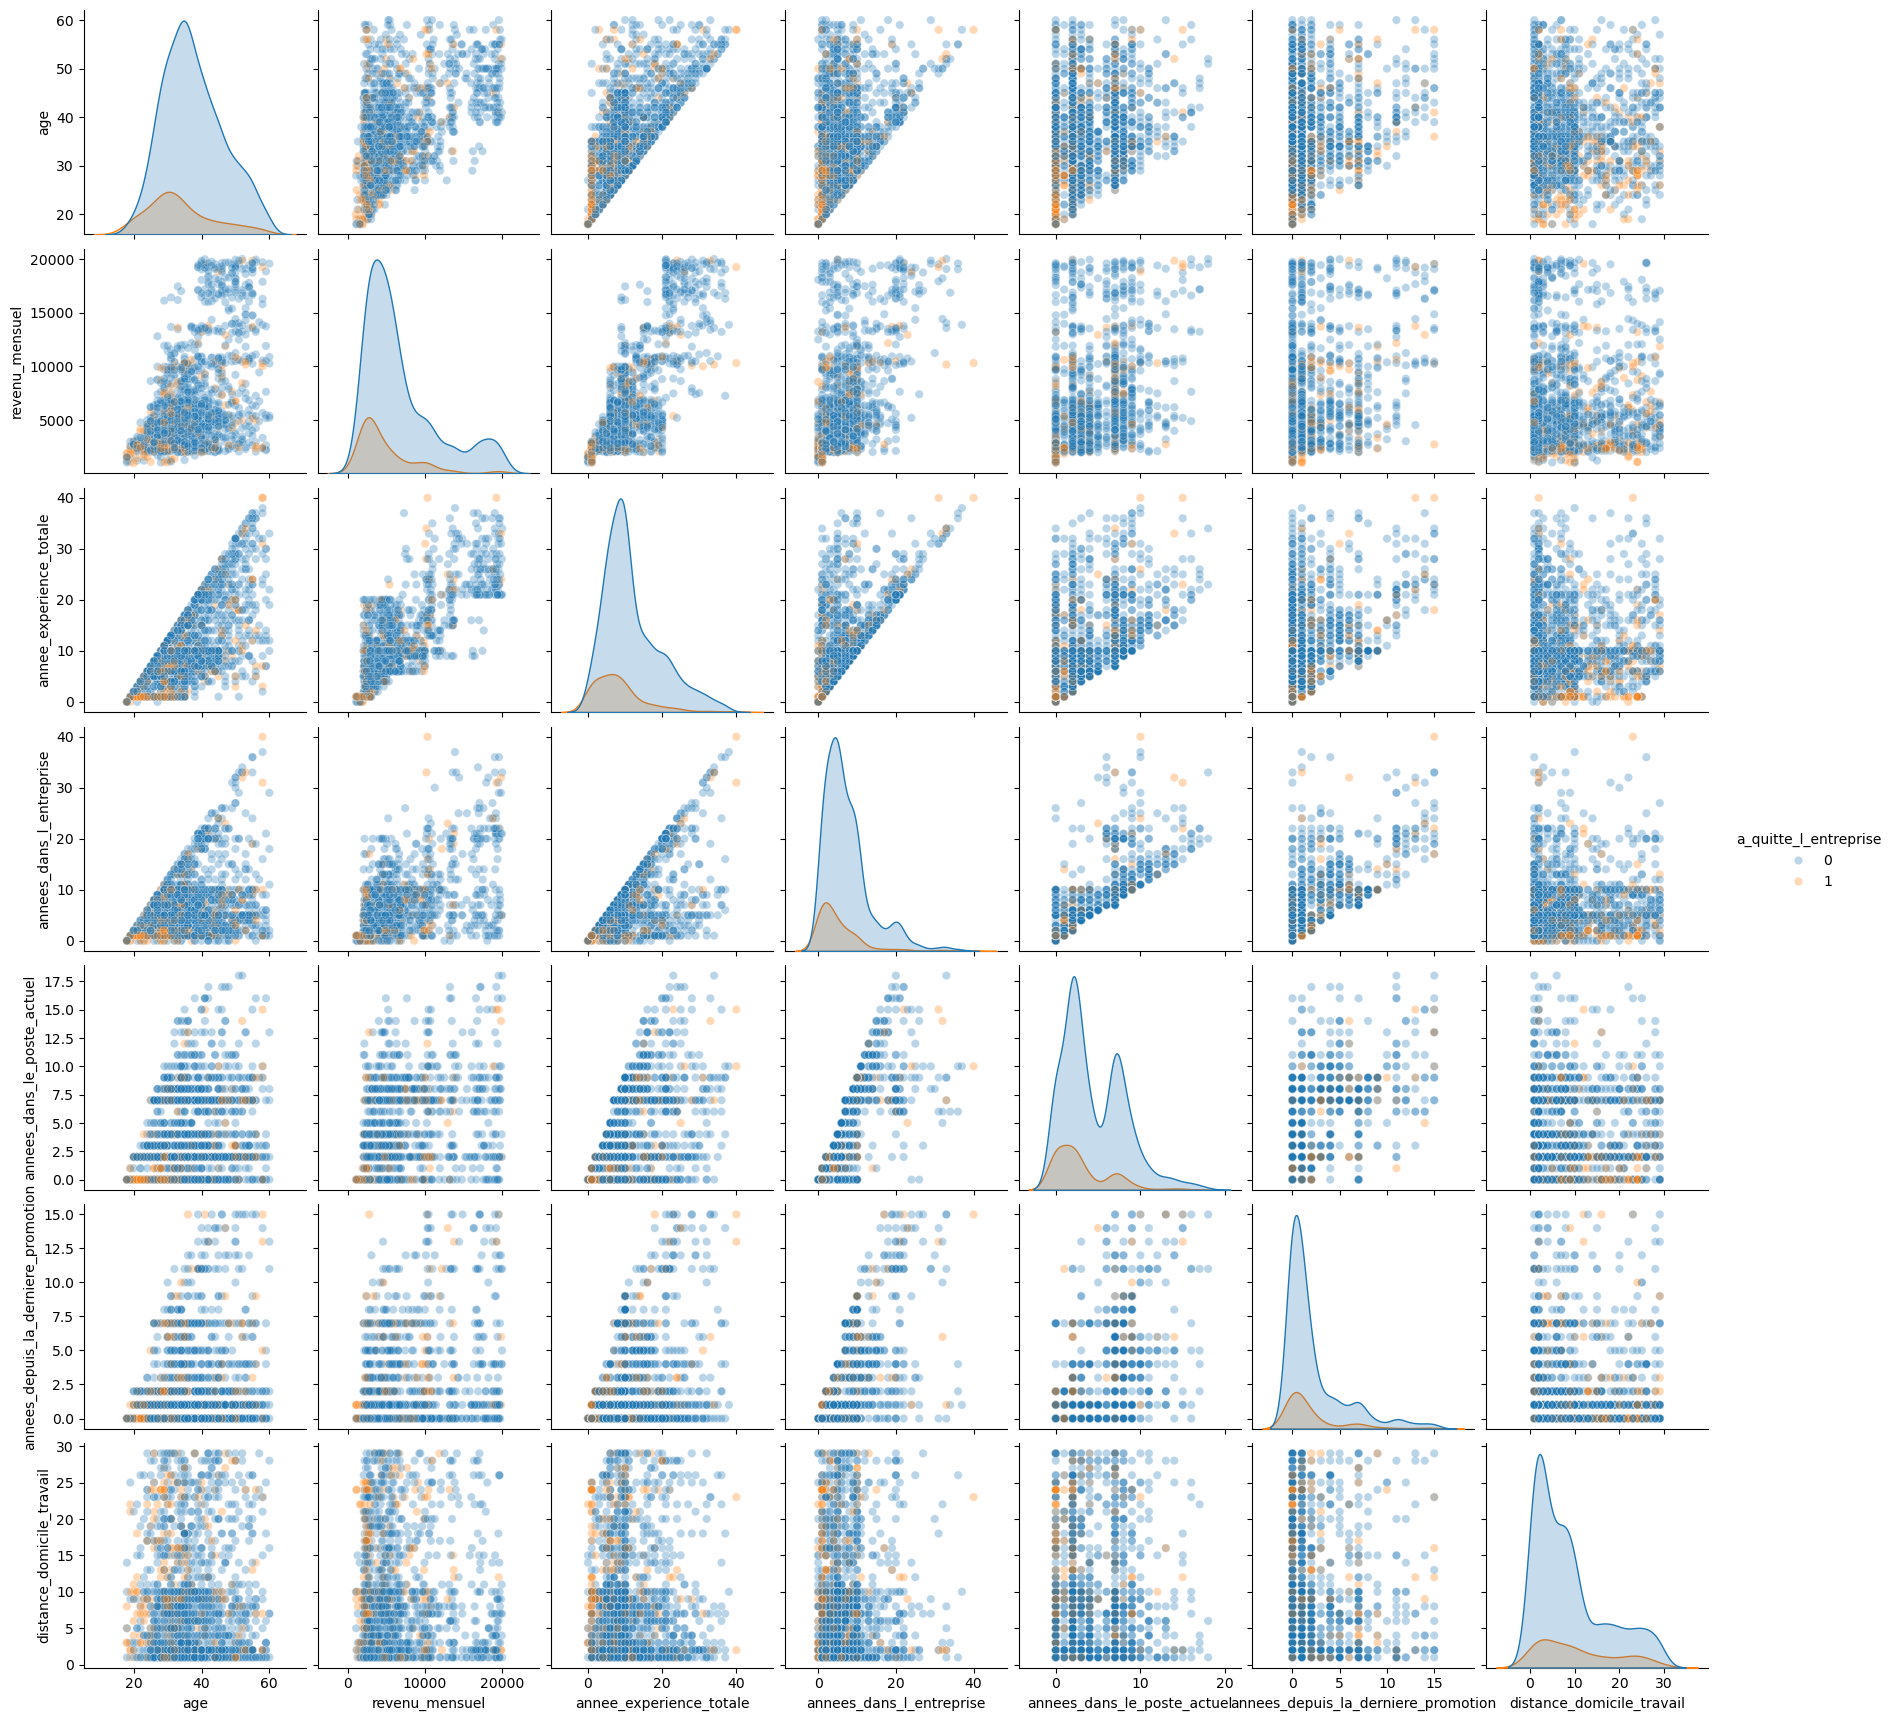

In [5]:
cols_focus = ['age', 'revenu_mensuel', 'annee_experience_totale', 
              'annees_dans_l_entreprise', 'annees_dans_le_poste_actuel',
              'annees_depuis_la_derniere_promotion', 'distance_domicile_travail']

sns.pairplot(df[cols_focus + ['a_quitte_l_entreprise']], 
             hue='a_quitte_l_entreprise',
             plot_kws={'alpha': 0.3})
plt.show()

## X,y init + encodage des features

In [6]:
def encode_features(X, encoding_map):
    X = X.copy()
    cols_ohe = []
    
    for col, params in encoding_map.items():
        parts = params.split(',')
        enc_type = parts[0]
        
        if enc_type == 'asis': pass
       
        elif enc_type == 'bin':
            mapping = {}
            for p in parts[1:]:
                k, v = p.split('=')
                mapping[k] = int(v)
            X[f'~bin_{col}'] = X[col].map(mapping)
            X = X.drop(columns=[col])
        
        elif enc_type == 'ohe': cols_ohe.append(col)
        
        elif enc_type == 'ord':
            categories = parts[1:]
            enc = OrdinalEncoder(categories=[categories])
            X[f'~ord_{col}'] = enc.fit_transform(X[[col]])
            X = X.drop(columns=[col])
    
    if cols_ohe: X = pd.get_dummies(X, columns=cols_ohe, prefix={c: f'~ohe_{c}' for c in cols_ohe}, dtype=int) #, drop_first=True)
    
    return X

encoding_map = {
    'genre':                            "bin,M=1,F=0",
    'statut_marital':                   'ohe',
#    'departement':                     'ohe',
    'poste':                            'ohe',
    'domaine_etude':                    'ohe',   
#    'nombre_experiences_precedentes':   'ohe',                                       #Zetest
    'frequence_deplacement':            'ord,Aucun,Occasionnel,Frequent',
}

y = df[latarget]

X = df.drop(columns=[latarget])
X = encode_features(X, encoding_map)

describoost(X,sorting_column='index')


==================== 🚀 DESCRIBOOST : Dataset ====================
Nbre de lignes  : 1470 
Nbre de colonnes: 41 

--- ANALYSE NUMÉRIQUE ---
                                             count     mean      std     min     25%     50%     75%      max skewsc mean/md Minidist  NaNs      Remarque   Suggestion
age                                         1470.0    36.92     9.14    18.0    30.0    36.0    43.0     60.0    0.3     1.0     ▄▄▄▄   0.0             -            -
annee_experience_totale                     1470.0    11.28     7.78     0.0     6.0    10.0    15.0     40.0    2.0     1.1     ▄█▄_   0.0             -            -
annees_dans_l_entreprise                    1470.0     7.01     6.13     0.0     3.0     5.0     9.0     40.0    6.0     1.4     ███_   0.0  R-outlier(s)  log?/suppr?
annees_dans_le_poste_actuel                 1470.0     4.23     3.62     0.0     2.0     3.0     7.0     18.0    4.0     1.4     ██▄_   0.0  R-outlier(s)  log?/suppr?
annees_depuis_la_derniere

## Train Test split

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y
)

print(y_train.value_counts(normalize=True).round(2))
print(y_test.value_counts(normalize=True).round(2))

lescaler=StandardScaler()
X_train_sc = lescaler.fit_transform(X_train)
X_test_sc = lescaler.transform(X_test)

a_quitte_l_entreprise
0    0.84
1    0.16
Name: proportion, dtype: float64
a_quitte_l_entreprise
0    0.84
1    0.16
Name: proportion, dtype: float64


## Models testing & scoring

In [8]:
# print multicolonnes functions

mcp_memo = [[]]

def printnotyet(stufftoprint):
    for line in stufftoprint.split('\n'):
        mcp_memo[-1].append(line)  # on append à la dernière col

def newcol():
    mcp_memo.append([])

def dotheprint(allsamecolwidth=False):
    global mcp_memo
    
    # calcul des largeurs
    col_widths = [max((len(line) for line in col), default=0) + 10 for col in mcp_memo]
    
    if allsamecolwidth:
        col_widths = [max(col_widths)] * len(mcp_memo)
    
    maxlines = max(len(c) for c in mcp_memo)
    for i in range(maxlines):
        print(''.join(
            f"{mcp_memo[c][i]:<{col_widths[c]}}" if i < len(mcp_memo[c]) else ' ' * col_widths[c]
            for c in range(len(mcp_memo))
        ))
    
    mcp_memo = [[]]

In [9]:
lesmodels = {
#    'DummyClassifier'                : DummyClassifier(strategy='stratified', random_state=42),  # strategy='stratified' > prédit aléatoirement en respectant le ratio des classes
    'LogisticRegression/balanced'    : LogisticRegression(random_state=42, max_iter=1000, class_weight='balanced'),
    'RandomForest/balanced'          : RandomForestClassifier(random_state=42, class_weight='balanced'),
    'GradientBoosting'               : GradientBoostingClassifier(random_state=42),
    'XGBoost/balanced'               : XGBClassifier(random_state=42, verbosity=0, scale_pos_weight=5),   # cf balanced
}

print("============================ " + datetime.now().strftime("%Y-%m-%d %H:%M:%S") + " =========================== ") 
print()
if True :   # avec cross_valid
 for lemodelname, lemodel in lesmodels.items():
    scores = cross_validate(lemodel, X_train_sc, y_train, 
                            cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
                            scoring=['recall', 'precision', 'f1', 'roc_auc'],
                            return_train_score=True)
    printnotyet(f">>> {lemodelname.upper()} === Train cv scores ===")
    printnotyet(f"  Recall    train: {scores['train_recall'].mean():.2f} ± {scores['train_recall'].std():.2f}  |  tr_test: {scores['test_recall'].mean():.2f} ± {scores['test_recall'].std():.2f}")
    printnotyet(f"  Precision train: {scores['train_precision'].mean():.2f} ± {scores['train_precision'].std():.2f}  |  tr_test: {scores['test_precision'].mean():.2f} ± {scores['test_precision'].std():.2f}")
    printnotyet(f"  F1        train: {scores['train_f1'].mean():.2f} ± {scores['train_f1'].std():.2f}  |  tr_test: {scores['test_f1'].mean():.2f} ± {scores['test_f1'].std():.2f}")
    printnotyet(f"  ROC-AUC   train: {scores['train_roc_auc'].mean():.2f} ± {scores['train_roc_auc'].std():.2f}  |  tr_test: {scores['test_roc_auc'].mean():.2f} ± {scores['test_roc_auc'].std():.2f}")

    lemodel.fit(X_train_sc, y_train)
    cm = confusion_matrix(y_train, lemodel.predict(X_train_sc))
    printnotyet(f"\n                        Prédit 0   Prédit 1")
    printnotyet(f"  Réel 0  (tot={cm[0].sum():>4})   {cm[0][0]:>8} {cm[0][1]:>8}")
    printnotyet(f"  Réel 1  (tot={cm[1].sum():>4})   {cm[1][0]:>8} {cm[1][1]:>8}")

    newcol()

    cr = classification_report(y_test, lemodel.predict(X_test_sc), output_dict=True)
    # On calcule l'AUC séparément avec les PROBABILITÉS (predict_proba)
    # [:, 1] pour ne garder que la colonne de probabilité de la classe 1 (le départ)
    auc_test = roc_auc_score(y_test, lemodel.predict_proba(X_test_sc)[:, 1])
    printnotyet("        === Test scores ===")
    printnotyet(f"  Recall    test: {cr['1']['recall']:.2f}")
    printnotyet(f"  Precision test: {cr['1']['precision']:.2f}")
    printnotyet(f"  F1        test: {cr['1']['f1-score']:.2f}")
    printnotyet(f"  ROC-AUC   test: {auc_test:.2f}")
    
    cm = confusion_matrix(y_test, lemodel.predict(X_test_sc))
    printnotyet(f"\n                        Prédit 0   Prédit 1")
    printnotyet(f"  Réel 0  (tot={cm[0].sum():>4})   {cm[0][0]:>8} {cm[0][1]:>8}")
    printnotyet(f"  Réel 1  (tot={cm[1].sum():>4})   {cm[1][0]:>8} {cm[1][1]:>8}")

    dotheprint()
    print()


else :    # no cross_valid
 for lemodelname, lemodel in lesmodels.items():
    lemodel.fit(X_train_sc, y_train)

    printnotyet(f">>> {lemodelname.upper():<20} === Train ===")
    printnotyet(classification_report(y_train, lemodel.predict(X_train_sc)).replace("\n\n", "\n"))

    cm = confusion_matrix(y_train, lemodel.predict(X_train_sc))
    printnotyet(f"                        Prédit 0   Prédit 1")
    printnotyet(f"  Réel 0  (tot={cm[0].sum():>4})   {cm[0][0]:>8} {cm[0][1]:>8}")
    printnotyet(f"  Réel 1  (tot={cm[1].sum():>4})   {cm[1][0]:>8} {cm[1][1]:>8}")

    newcol()
    printnotyet(" "*25+"=== Test ===")
    printnotyet(classification_report(y_test, lemodel.predict(X_test_sc)).replace("\n\n", "\n"))

    cm = confusion_matrix(y_test, lemodel.predict(X_test_sc))
    printnotyet(f"                        Prédit 0   Prédit 1")
    printnotyet(f"  Réel 0  (tot={cm[0].sum():>4})   {cm[0][0]:>8} {cm[0][1]:>8}")
    printnotyet(f"  Réel 1  (tot={cm[1].sum():>4})   {cm[1][0]:>8} {cm[1][1]:>8}")
    dotheprint()
    print()
    print()
    

============================ 2026-05-13 14:28:31 =========================== 

>>> LOGISTICREGRESSION/BALANCED === Train cv scores ===                  === Test scores ===                          
  Recall    train: 0.81 ± 0.00  |  tr_test: 0.72 ± 0.08            Recall    test: 0.72                               
  Precision train: 0.42 ± 0.01  |  tr_test: 0.37 ± 0.04            Precision test: 0.39                               
  F1        train: 0.55 ± 0.01  |  tr_test: 0.49 ± 0.03            F1        test: 0.50                               
  ROC-AUC   train: 0.88 ± 0.01  |  tr_test: 0.83 ± 0.03            ROC-AUC   test: 0.81                               
                                                                                                                      
                        Prédit 0   Prédit 1                                              Prédit 0   Prédit 1          
  Réel 0  (tot= 986)        766      220                           Réel 0  (tot= 247)   

## Grisearch

In [10]:
from sklearn.metrics import make_scorer, recall_score, precision_score, f1_score, roc_auc_score

lescoring = {
    'recall'    : make_scorer(recall_score, pos_label=1),
    'precision' : make_scorer(precision_score, pos_label=1, zero_division=0),
    'f1'        : make_scorer(f1_score, pos_label=1, zero_division=0),
    'roc_auc'   : 'roc_auc'
}

def gridsearch_model(lemodelname, lemodel, param_grid, lerefit="recall"):
    param_grid = param_grid.copy()
    print(f"\n>>> {lemodelname.upper()}   ========= Gridsearch (refit="+lerefit+')')
    grid = GridSearchCV(
        lemodel, param_grid,
        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
        scoring=lescoring,
        refit=lerefit,
        return_train_score=True,
        n_jobs=-1
    )
    grid.fit(X_train_sc, y_train)
    results = grid.cv_results_
    best = grid.best_index_
    printnotyet("Best params:"+23*' ')
    printnotyet(f"{str(grid.best_params_).replace(',','\n').replace('{', ' ').replace('}', '').replace(':', '=')}")
    newcol()
    printnotyet(f"  Recall cv    : {results['mean_test_recall'][best]:.2f} ± {results['std_test_recall'][best]:.2f}")
    printnotyet(f"  Precision cv : {results['mean_test_precision'][best]:.2f} ± {results['std_test_precision'][best]:.2f}")
    printnotyet(f"  F1 cv        : {results['mean_test_f1'][best]:.2f} ± {results['std_test_f1'][best]:.2f}")
    printnotyet(f"  ROC AUC cv   : {results['mean_test_roc_auc'][best]:.2f} ± {results['std_test_roc_auc'][best]:.2f}")
    dotheprint()
    print()
    return grid.best_estimator_

def scoretest(lemodelname, best_model, threshold=0.5,thequote=''):
    y_proba = best_model.predict_proba(X_test_sc)[:, 1]
    y_pred = (y_proba >= threshold).astype(int)
    report = classification_report(y_test, y_pred, output_dict=True, zero_division=0)
    auc_test = roc_auc_score(y_test, y_proba) # Calcul de l'AUC test
    cm = confusion_matrix(y_test, y_pred)
    printnotyet(f"  --- Test scores (seuil {threshold:.2f}) --->")
    printnotyet(thequote.center(36))
    newcol()
    printnotyet(f"  Recall    : {report['1']['recall']:.2f}")
    printnotyet(f"  Precision : {report['1']['precision']:.2f}")
    printnotyet(f"  F1        : {report['1']['f1-score']:.2f}")
    printnotyet(f"  AUC test  : {auc_test:.2f}")
    newcol()
    tn=cm[0][0]
    fp=cm[0][1]
    fn=cm[1][0]
    vp=cm[1][1]
    tauxdedetection=vp/(vp+fn)
    tauxdefaussealerte=fp/(fp+tn)
    printnotyet(f"                       Prédit 0   Prédit 1")
    printnotyet(f"  Réel 0  (tot={cm[0].sum():>4})  {tn:>8} {fp:>8}   Fausse alertes: {tauxdefaussealerte:.2f}")
    printnotyet(f"  Réel 1  (tot={cm[1].sum():>4})  {fn:>8} {vp:>8}   Recall (detection) {tauxdedetection:.2f}")
    printnotyet("")
    dotheprint()

In [11]:
def findbestthreshold(lemodelname, best_model, thescoring='f1', precisionmin=0, recallmin=0):
    y_proba = best_model.predict_proba(X_test_sc)[:, 1]
    
    thresholds = np.linspace(0.01, 0.99, 100)
    best_threshold = 0.5 # Valeur par défaut
    best_score = -1
    
    for t in thresholds:
        y_pred = (y_proba >= t).astype(int)
        
        # Calcul des métriques pour ce seuil
        prec = precision_score(y_test, y_pred, zero_division=0)
        rec = recall_score(y_test, y_pred, zero_division=0)
        f1 = f1_score(y_test, y_pred, zero_division=0)
        
        # Vérification des contraintes (Garde-fous)
        if prec >= precisionmin and rec >= recallmin:
            # On choisit le score à optimiser
            current_score = f1 if thescoring == 'f1' else rec
            
            if current_score > best_score:
                best_score = current_score
                best_threshold = t
    
    if best_score == -1:
        print(f"  /!\ Aucun seuil ne respecte les contraintes (Prec > {precisionmin} & Rec > {recallmin})")
        return 0.5 # Retourne le seuil par défaut si échec
        
    return best_threshold

In [12]:
lesparams = {
    'LogisticRegression/balanced' : {
        'C': [0.005, 0.01, 0.02, 0.03],
        'solver': ['lbfgs', 'liblinear','newton-cg'],
    },
    'RandomForest/balanced' : {
        'n_estimators': [200], # On fixe à une valeur solide pour gagner du temps
        'max_depth': [5, 10, 15],
        'min_samples_leaf': [3, 5, 10], # Indispensable pour calmer l'overfitting du RF
    },
    'GradientBoosting' : {
        'n_estimators': [200, 300],
        'learning_rate': [0.01, 0.05],
        'max_depth': [3, 4],
        'min_samples_leaf': [3, 5], # Très utile ici aussi
    },
    'XGBoost/balanced' : {
        'n_estimators': [50, 100, 200, 300, 350],
        'max_depth': [3, 4, 5],
        'learning_rate': [0.01, 0.05, 0.1],
    },
}
dotheprint()
for lemodelname, lemodel in lesmodels.items():
    best_model = gridsearch_model(lemodelname, lemodel, lesparams[lemodelname],lerefit='roc_auc')  # lerefit = AUC
    scoretest(lemodelname, best_model)
    print()
    seuilf1=findbestthreshold(lemodelname,best_model,thescoring='f1')
    scoretest(lemodelname, best_model,threshold=seuilf1,thequote='(best F1)')
    print()
    seuilrecall=findbestthreshold(lemodelname,best_model,thescoring='recall',precisionmin=0.35)
    scoretest(lemodelname, best_model,threshold=seuilrecall,thequote='(best recall with precision>=0.35)')



>>> LOGISTICREGRESSION/BALANCED   ========= Gridsearch (refit=roc_auc)
Best params:                                   Recall cv    : 0.74 ± 0.08          
 'C'= 0.02                                     Precision cv : 0.39 ± 0.01          
 'solver'= 'lbfgs'                             F1 cv        : 0.51 ± 0.02          
                                               ROC AUC cv   : 0.84 ± 0.03          

  --- Test scores (seuil 0.50) --->             Recall    : 0.74                                 Prédit 0   Prédit 1                                 
                                                Precision : 0.43            Réel 0  (tot= 247)       200       47   Fausse alertes: 0.19             
                                                F1        : 0.54            Réel 1  (tot=  47)        12       35   Recall (detection) 0.74          
                                                AUC test  : 0.82                                                                             

## Initialisation des modeles choisis avec best params

In [13]:
# 1. ============================================ Logistic Regression
logreg_model = LogisticRegression(
    C=0.02, 
    solver='lbfgs', 
    class_weight='balanced', 
    random_state=42
)
logreg_model.fit(X_train_sc, y_train)
y_pred_log = logreg_model.predict(X_test_sc)

# 2. ============================================ GradientBoosting
gb_model = GradientBoostingClassifier(
    learning_rate=0.1,
    max_depth=3,
    n_estimators=200,
    random_state=42
)
gb_model.fit(X_train_sc, y_train)

y_probs_gb = gb_model.predict_proba(X_test_sc)[:, 1]   # On récupère la probabilité de la classe 1 (ceux qui partent)
y_pred_gb = (y_probs_gb >= 0.15).astype(int)           # On applique le seuil de 0.15

## Courbe PR/seuil

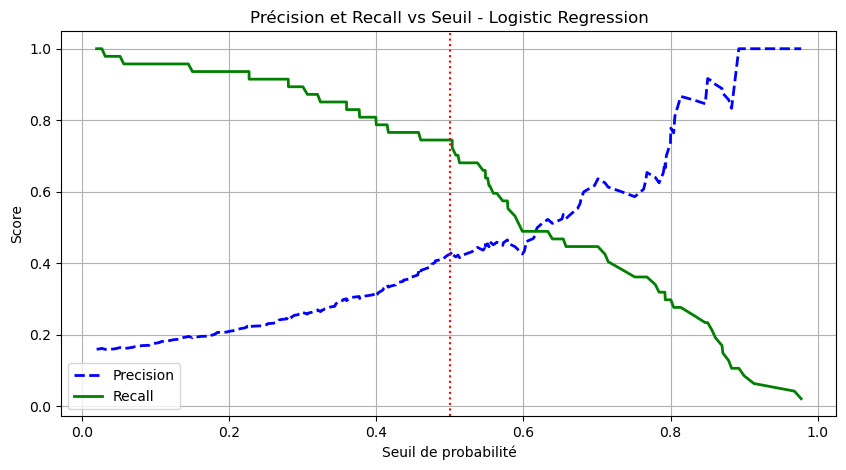

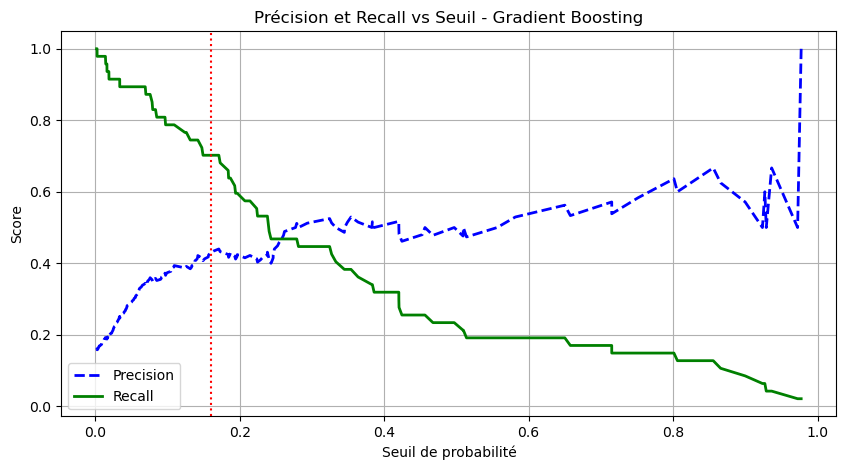

In [14]:
def plot_precision_recall_vs_threshold(model, X_test, y_test, title,zethreshold):
    # Récupération des probabilités
    y_probs = model.predict_proba(X_test)[:, 1]
    precisions, recalls, thresholds = precision_recall_curve(y_test, y_probs)

    plt.figure(figsize=(10, 5))
    # On affiche Precision et Recall en fonction des seuils
    plt.plot(thresholds, precisions[:-1], "b--", label="Precision", linewidth=2)
    plt.plot(thresholds, recalls[:-1], "g-", label="Recall", linewidth=2)
    
    # Mise en forme
    plt.title(f'Précision et Recall vs Seuil - {title}')
    plt.xlabel("Seuil de probabilité")
    plt.ylabel("Score")
    plt.legend(loc="best")
    plt.grid(True)
    plt.axvline(x=zethreshold, color='red', linestyle=':', label=f'Seuil choisi ({zethreshold})') # Ligne repère
    plt.show()

# Affichage pour la Régression Logistique
plot_precision_recall_vs_threshold(logreg_model, X_test_sc, y_test, "Logistic Regression", 0.5)

# Affichage pour le Gradient Boosting
plot_precision_recall_vs_threshold(gb_model, X_test_sc, y_test, "Gradient Boosting", 0.16)

## Courbes *kde* distrib des scores de proba

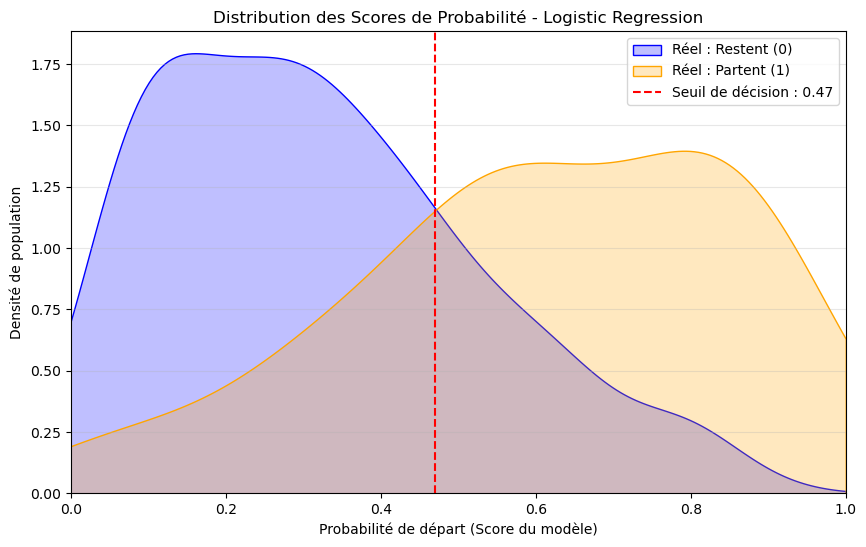

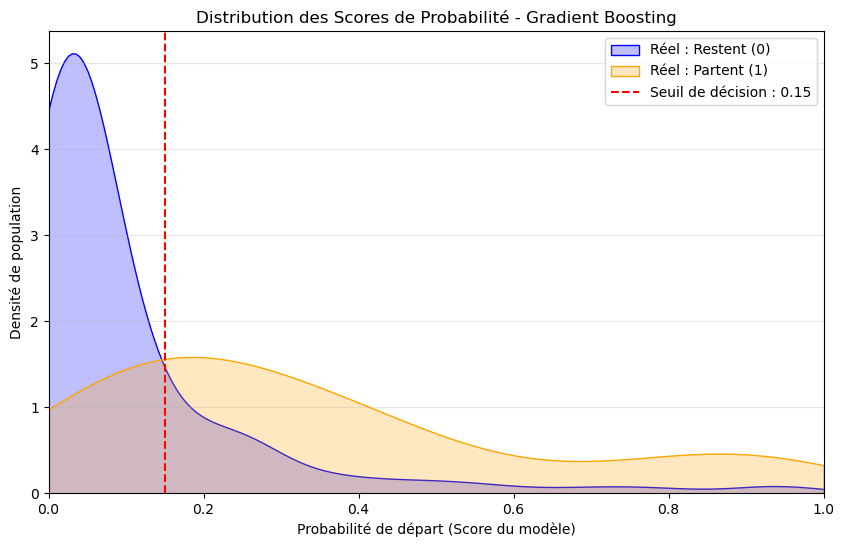

In [15]:
def plot_probability_distribution(model, X_test, y_test, title, zethreshold):
    # 1. Récupération des probabilités de la classe 1
    y_probs = model.predict_proba(X_test)[:, 1]
    
    plt.figure(figsize=(10, 6))
    
    # 2. Distribution pour ceux qui restent (0)
    sns.kdeplot(y_probs[y_test == 0], 
                label='Réel : Restent (0)', 
                fill=True, color='blue', 
                clip=(0, 1), bw_adjust=1)
    
    # 3. Distribution pour ceux qui partent (1)
    sns.kdeplot(y_probs[y_test == 1], 
                label='Réel : Partent (1)', 
                fill=True, color='orange', 
                clip=(0, 1), bw_adjust=1)
    
    # 4. Ajout du seuil et des limites
    plt.axvline(x=zethreshold, color='red', linestyle='--', 
                label=f'Seuil de décision : {zethreshold}')
    
    plt.xlim(0, 1)
    plt.title(f'Distribution des Scores de Probabilité - {title}')
    plt.xlabel('Probabilité de départ (Score du modèle)')
    plt.ylabel('Densité de population')
    plt.legend()
    plt.grid(axis='y', alpha=0.3)
    plt.show()

# --- Exécution ---

# Pour la LogReg (Seuil par défaut 0.5)
plot_probability_distribution(logreg_model, X_test_sc, y_test, "Logistic Regression", 0.47)

# Pour le Gradient Boosting (Ton seuil optimisé 0.16)
plot_probability_distribution(gb_model, X_test_sc, y_test, "Gradient Boosting", 0.15)

## Feature importance (native)

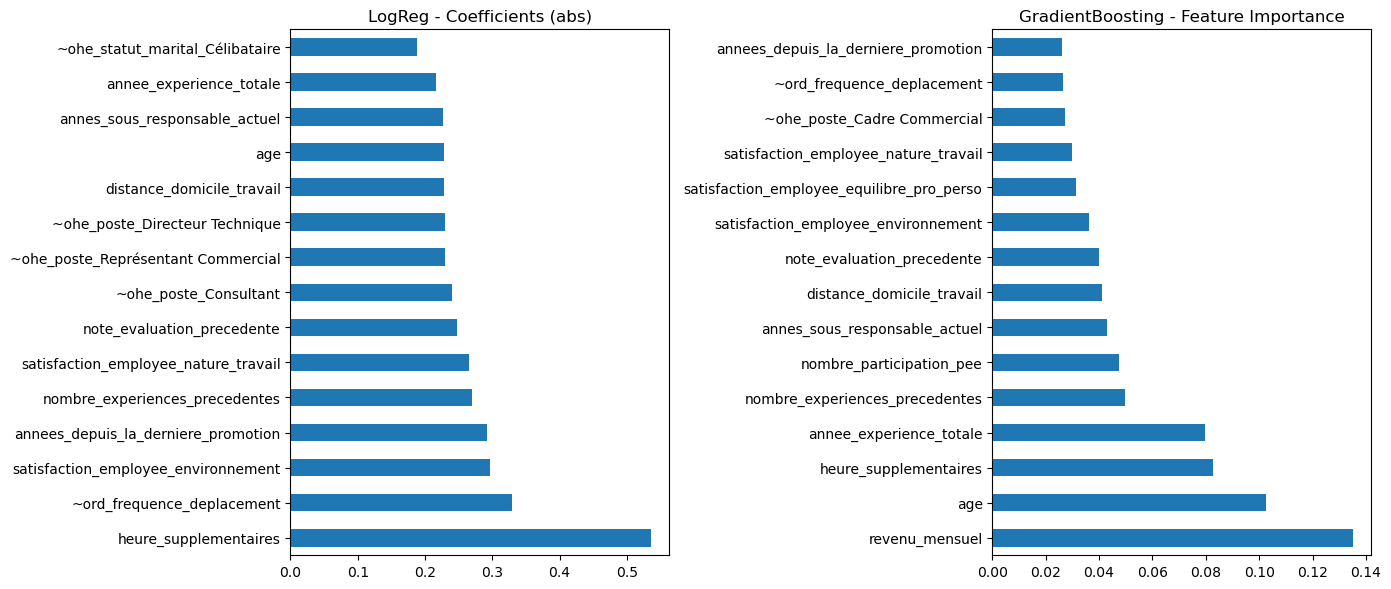

In [16]:
# LogReg — pas de feature_importances_, mais les coefficients
logreg_importances = pd.Series(logreg_model.coef_[0], index=X_train.columns).abs().sort_values(ascending=False)

# GradientBoosting — feature importance native
gb_importances = pd.Series(gb_model.feature_importances_, index=X_train.columns).sort_values(ascending=False)

# Top 15 features
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

logreg_importances.head(15).plot(kind='barh', ax=axes[0], title='LogReg - Coefficients (abs)')
gb_importances.head(15).plot(kind='barh', ax=axes[1], title='GradientBoosting - Feature Importance')

plt.tight_layout()
plt.show()

## Feature importance SHAP

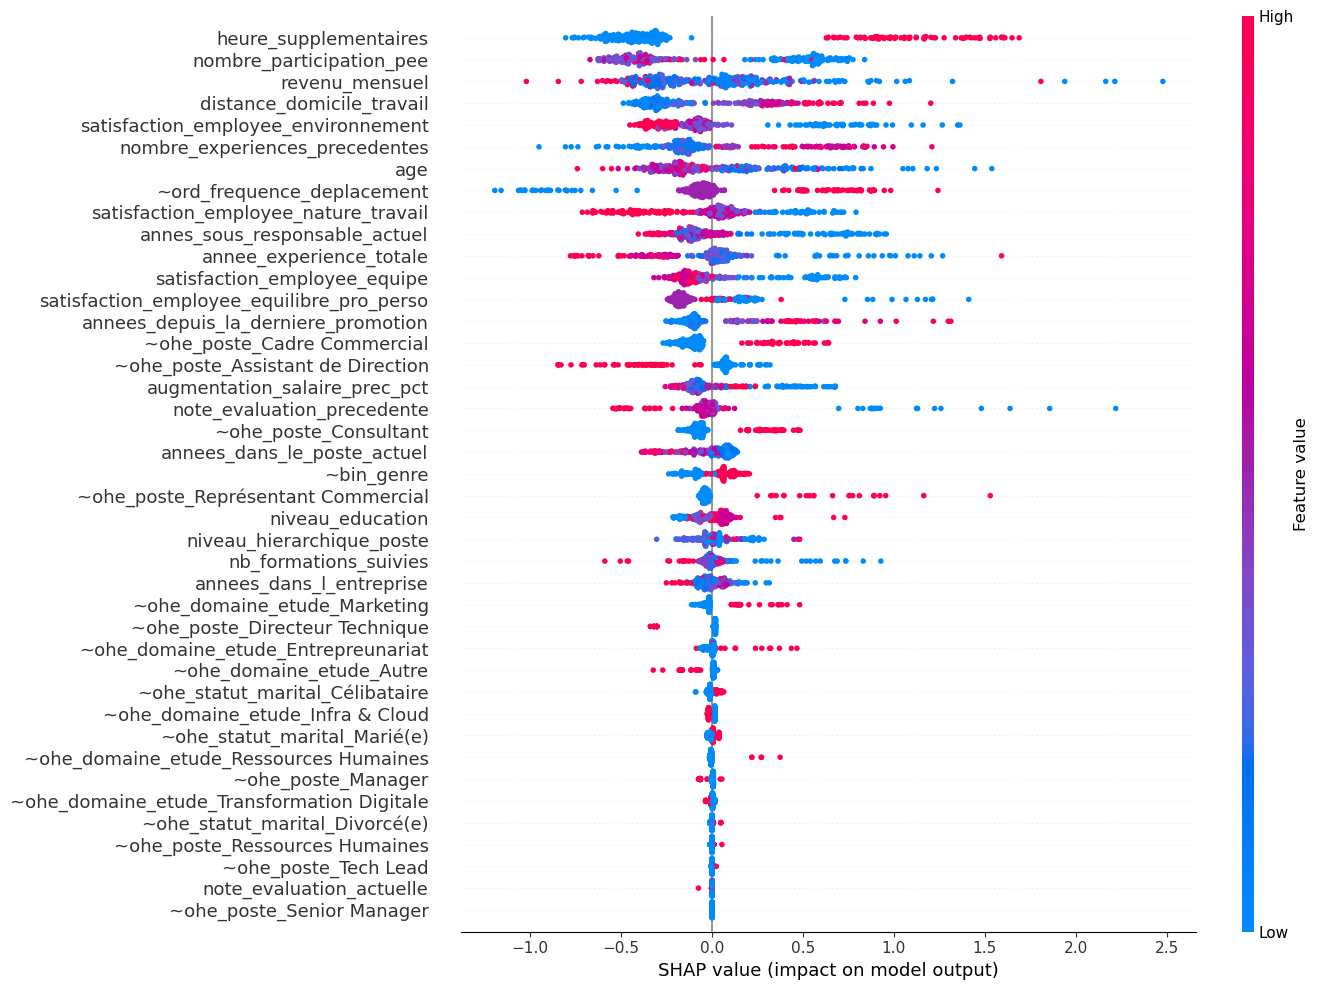

In [17]:
# **************************************************************  GradientBoosting — TreeExplainer (recommandé pour les arbres)
explainer_gb = shap.TreeExplainer(gb_model)
shap_values_gb = explainer_gb.shap_values(X_test_sc)

# Beeswarm plot — feature importance globale
shap.summary_plot(shap_values_gb, X_test_sc, feature_names=X_train.columns, plot_size=(14, 10),max_display=50)

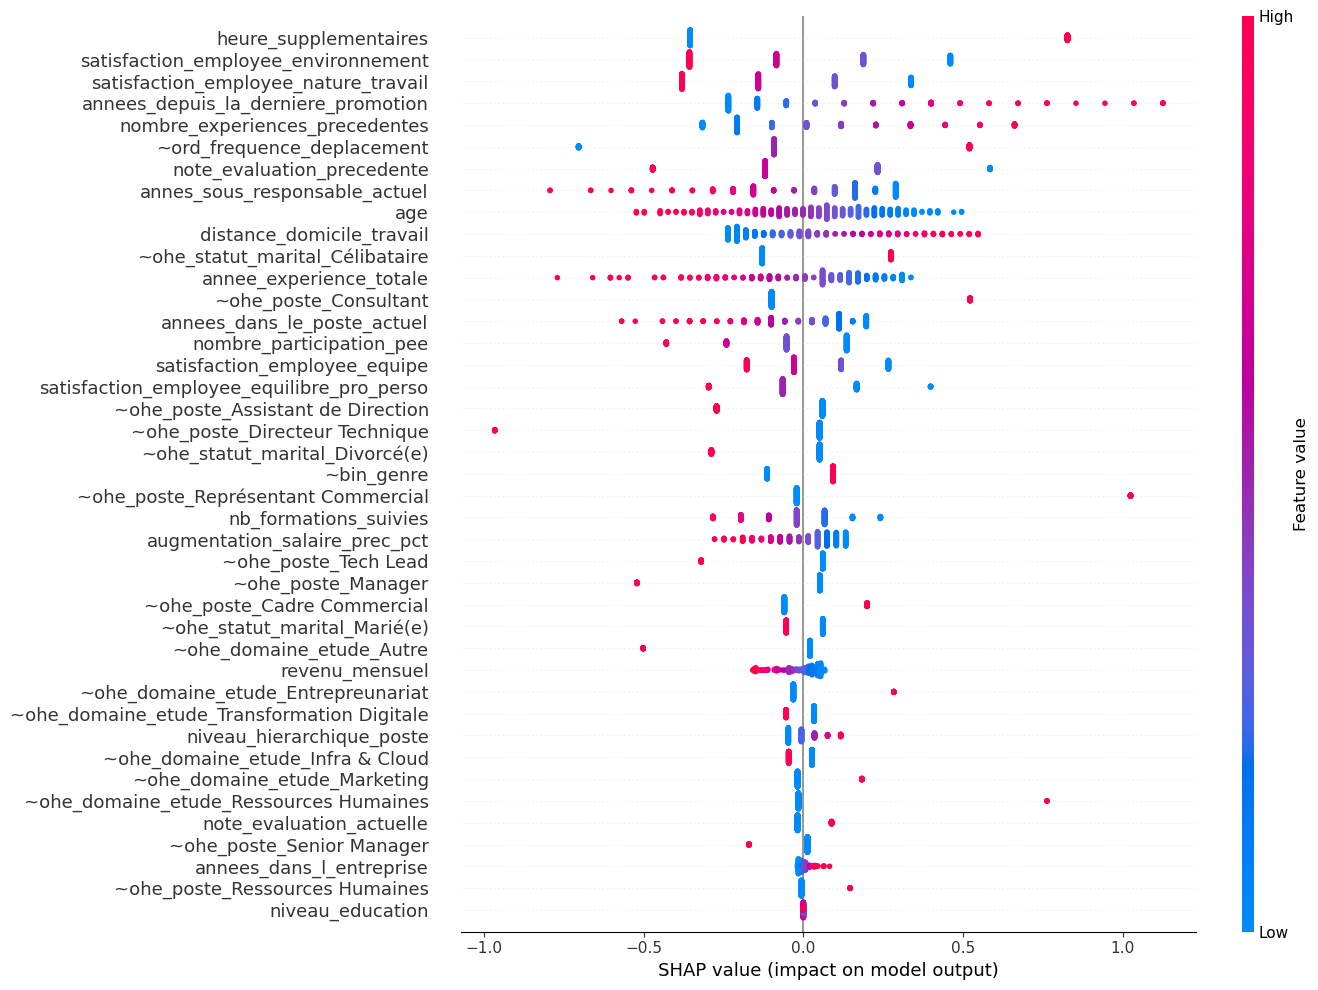

In [18]:
# **************************************************************  GradientBoosting — LinearExplainer
explainer_lr = shap.LinearExplainer(logreg_model, X_train_sc)
shap_values_lr = explainer_lr.shap_values(X_test_sc)

# Beeswarm plot — feature importance globale
shap.summary_plot(shap_values_lr, X_test_sc, feature_names=X_train.columns, plot_size=(14, 10),max_display=50)

## Features poussant au départ

In [19]:
# Features où valeur élevée pousse au DEPART (rouge à droite)

shap_direction = pd.Series(
    [np.corrcoef(X_test_sc[:, i], shap_values_gb[:, i])[0, 1]      # Corrélation entre valeur feature et SHAP value GBoost
     for i in range(X_test_sc.shape[1])],
    index=X_train.columns
).fillna(0)  # remplace les NaN (division par zéro) par 0
rouge_droite_gb = shap_direction[shap_direction > 0].sort_values(ascending=False)                   # GBoost

rouge_droite_lr = pd.Series(logreg_model.coef_[0], index=X_train.columns)                           # LogReg
rouge_droite_lr = rouge_droite_lr[rouge_droite_lr > 0].sort_values(ascending=False)

common_droite = rouge_droite_gb.index.intersection(rouge_droite_lr.index)                           # Common
rouge_droite_both = (rouge_droite_gb[common_droite] + rouge_droite_lr[common_droite]).sort_values(ascending=False)

print("*"*40+' Feature poussant au depart ' +"*"*40)

printnotyet("              ====== Log Reg ======")
printnotyet(str(rouge_droite_lr).replace('dtype: float64',''))
newcol()
printnotyet("              ====== GBoost ======")
printnotyet(str(rouge_droite_gb).replace('dtype: float64',''))
newcol()
printnotyet("              ====== Both ======")
printnotyet(str(rouge_droite_both).replace('dtype: float64',''))
dotheprint()


**************************************** Feature poussant au depart ****************************************
              ====== Log Reg ======                                       ====== GBoost ======                                        ====== Both ======                            
heure_supplementaires                     0.535469          ~ohe_domaine_etude_Ressources Humaines    0.977001          heure_supplementaires                     1.500286          
~ord_frequence_deplacement                0.328554          ~ord_frequence_deplacement                0.968053          ~ord_frequence_deplacement                1.296607          
annees_depuis_la_derniere_promotion       0.291494          heure_supplementaires                     0.964817          annees_depuis_la_derniere_promotion       1.201934          
nombre_experiences_precedentes            0.269806          ~ohe_poste_Consultant                     0.960317          ~ohe_poste_Consultant                     1.200

c:\Users\jacob\anaconda3\Lib\site-packages\numpy\lib\_function_base_impl.py:3065: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\Users\jacob\anaconda3\Lib\site-packages\numpy\lib\_function_base_impl.py:3066: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


## Features poussant à rester

In [20]:
# Features où valeur élevée pousse à RESTER (rouge à gauche)

rouge_gauche_gb = shap_direction[shap_direction < 0].sort_values()                              # GBoost

rouge_gauche_lr = pd.Series(logreg_model.coef_[0], index=X_train.columns)                       # LogReg
rouge_gauche_lr = rouge_gauche_lr[rouge_gauche_lr < 0].sort_values()

common_gauche = rouge_gauche_gb.index.intersection(rouge_gauche_lr.index)                       # Common
rouge_gauche_both = (rouge_gauche_gb[common_gauche] + rouge_gauche_lr[common_gauche]).sort_values()

print("*"*40+' Features poussant à rester ' +"*"*40)

printnotyet("              ====== Log Reg ======")
printnotyet(str(rouge_gauche_lr).replace('dtype: float64',''))
newcol()
printnotyet("              ====== GBoost ======")
printnotyet(str(rouge_gauche_gb).replace('dtype: float64',''))
newcol()
printnotyet("              ====== Both ======")
printnotyet(str(rouge_gauche_both).replace('dtype: float64',''))
dotheprint()

#print(rouge_gauche_both)

**************************************** Features poussant à rester ****************************************
              ====== Log Reg ======                                           ====== GBoost ======                                            ====== Both ======                                
satisfaction_employee_environnement          -0.296318          ~ohe_poste_Directeur Technique               -0.999207          ~ohe_poste_Directeur Technique               -1.228182          
satisfaction_employee_nature_travail         -0.265400          ~ohe_domaine_etude_Infra & Cloud             -0.948408          satisfaction_employee_environnement          -1.150169          
note_evaluation_precedente                   -0.247600          ~ohe_domaine_etude_Autre                     -0.921330          satisfaction_employee_nature_travail         -1.146695          
~ohe_poste_Directeur Technique               -0.228975          ~ohe_poste_Assistant de Direction            -0.913285 

## Features neutres

In [21]:
# Features neutres
all_features = set(X_train.columns)
rouge_droite_set = set(rouge_droite_both.index)
rouge_gauche_set = set(rouge_gauche_both.index)

neutres = all_features - rouge_droite_set - rouge_gauche_set
print("*"*40+' Features neutres ' +"*"*40)
print('\n'.join(sorted(neutres)))

**************************************** Features neutres ****************************************
annees_dans_l_entreprise
niveau_education
niveau_hierarchique_poste
note_evaluation_actuelle
~ohe_poste_Senior Manager
~ohe_poste_Tech Lead
~ohe_statut_marital_Divorcé(e)
~ohe_statut_marital_Marié(e)


## Permutation Importance

In [22]:
def f1_with_threshold(y_true, y_proba, threshold=0.16):
    y_pred = (y_proba >= threshold).astype(int)
    return f1_score(y_true, y_pred)

custom_scorer = make_scorer(f1_with_threshold, response_method='predict_proba', threshold=0.16)

pigb = permutation_importance(gb_model, X_test_sc, y_test, 
                                n_repeats=10, random_state=42, scoring=custom_scorer)

perm_importance_gb = pd.Series(pigb.importances_mean, index=X_train.columns).sort_values(ascending=False)

pilr = permutation_importance(logreg_model, X_test_sc, y_test, 
                                n_repeats=10, random_state=42, scoring='recall')

perm_importance_lr = pd.Series(pilr.importances_mean, index=X_train.columns).sort_values(ascending=False)

common_pi = perm_importance_gb.head(25).index.intersection(perm_importance_lr.head(25).index)                       # Common
pi_both = (perm_importance_gb[common_pi] + perm_importance_lr[common_pi]).sort_values(ascending=False)

print("*"*40+' Permutation Importance ' +"*"*40)

printnotyet("              ====== GBoost ======")
printnotyet(str(perm_importance_gb.head(20)).replace('dtype: float64',''))
newcol()
printnotyet("              ====== Log Reg ======")
printnotyet(str(perm_importance_lr.head(20)).replace('dtype: float64',''))
newcol()
printnotyet("              ====== Both ======")
printnotyet(str(pi_both.head(20)).replace('dtype: float64',''))

dotheprint()

**************************************** Permutation Importance ****************************************
              ====== GBoost ======                                           ====== Log Reg ======                                     ====== Both ======                               
heure_supplementaires                        0.153323          heure_supplementaires                   0.161702          heure_supplementaires                        0.315025          
satisfaction_employee_environnement          0.055922          ~ord_frequence_deplacement              0.106383          satisfaction_employee_nature_travail         0.152428          
satisfaction_employee_nature_travail         0.054556          satisfaction_employee_nature_travail    0.097872          satisfaction_employee_environnement          0.126135          
nombre_participation_pee                     0.042197          nombre_experiences_precedentes          0.082979          ~ord_frequence_deplacement        

## fonction shap.plots.scatter() et son argument “color”

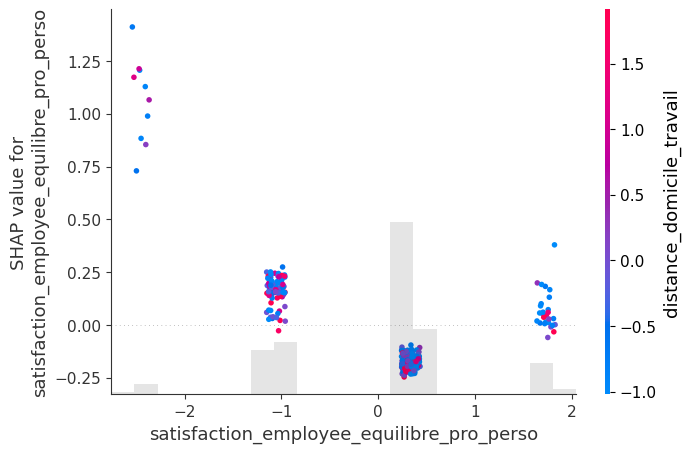

In [23]:
shap_expl_gb = explainer_gb(pd.DataFrame(X_test_sc, columns=X_train.columns))

shap.plots.scatter(shap_expl_gb[:, 'satisfaction_employee_equilibre_pro_perso'], 
                   color=shap_expl_gb[:, 'distance_domicile_travail'])

## Feature importance locale => Waterfall Plot

In [118]:
from scipy.special import logit

def mywaterfall(the_explanation,the_class=1,the_index=0,the_title='exemple',the_seuil=0.5,class1_tag='Positive',class0_tag='Negative'):
    row_idx = np.where(y_test == the_class)[0][the_index]

    exp_display = shap.Explanation(
        values=the_explanation[row_idx].values,
        base_values=the_explanation[row_idx].base_values,
        data=X_test.iloc[row_idx], # <--- On pointe sur le DF d'origine (âge, salaire réels)
        feature_names=X_test.columns
    )
    
    f_x = the_explanation[row_idx].base_values + np.sum(the_explanation[row_idx].values)
    seuil_logit = logit(the_seuil)
    the_prediction = class1_tag if f_x >= seuil_logit else class0_tag
    the_truth = class1_tag if the_class== 1 else class0_tag
    the_ref=f'c{the_class}-i{the_index}'

    plt.figure(figsize=(12, 6))
    shap.plots.waterfall(exp_display, show=False)

    plt.title(f"SHAP Waterfall (Seuil: {the_seuil} => logit: {seuil_logit:.2f})   "+the_title.center(60)+
              f" sample id:{the_ref}  ==> Prediction vs Real: {the_prediction}/{the_truth}     ", 
              fontsize=10, pad=10)   
    plt.axvline(x=logit(the_seuil), color='red', linestyle='--', alpha=0.6)
    plt.show()



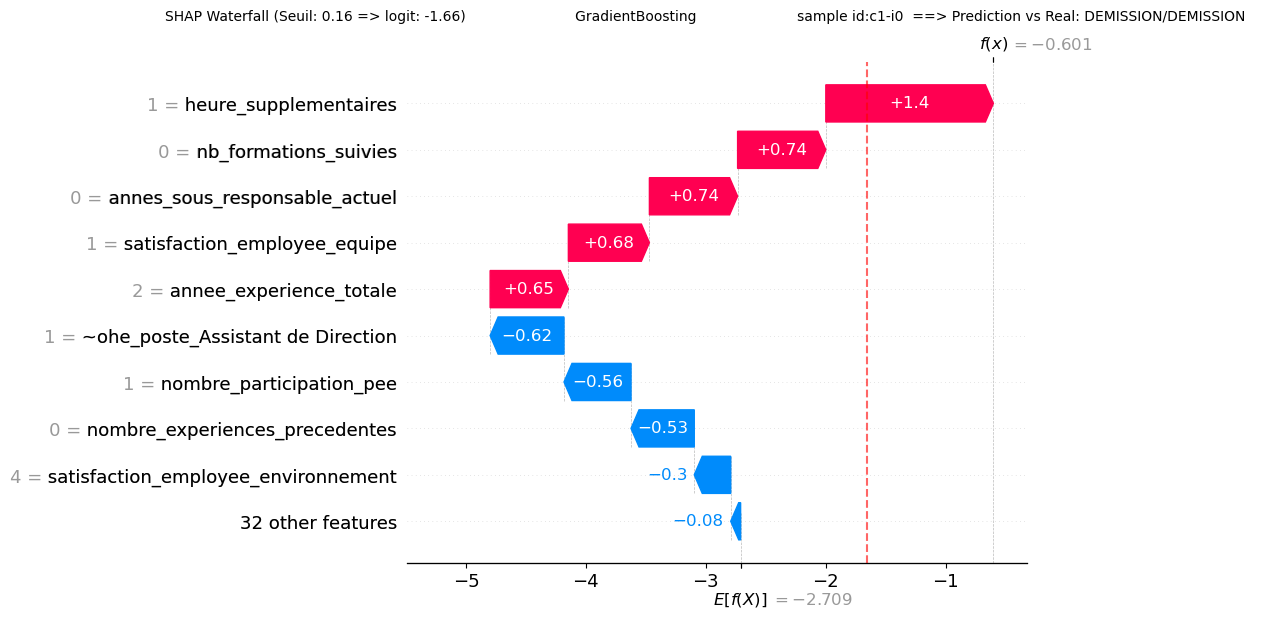

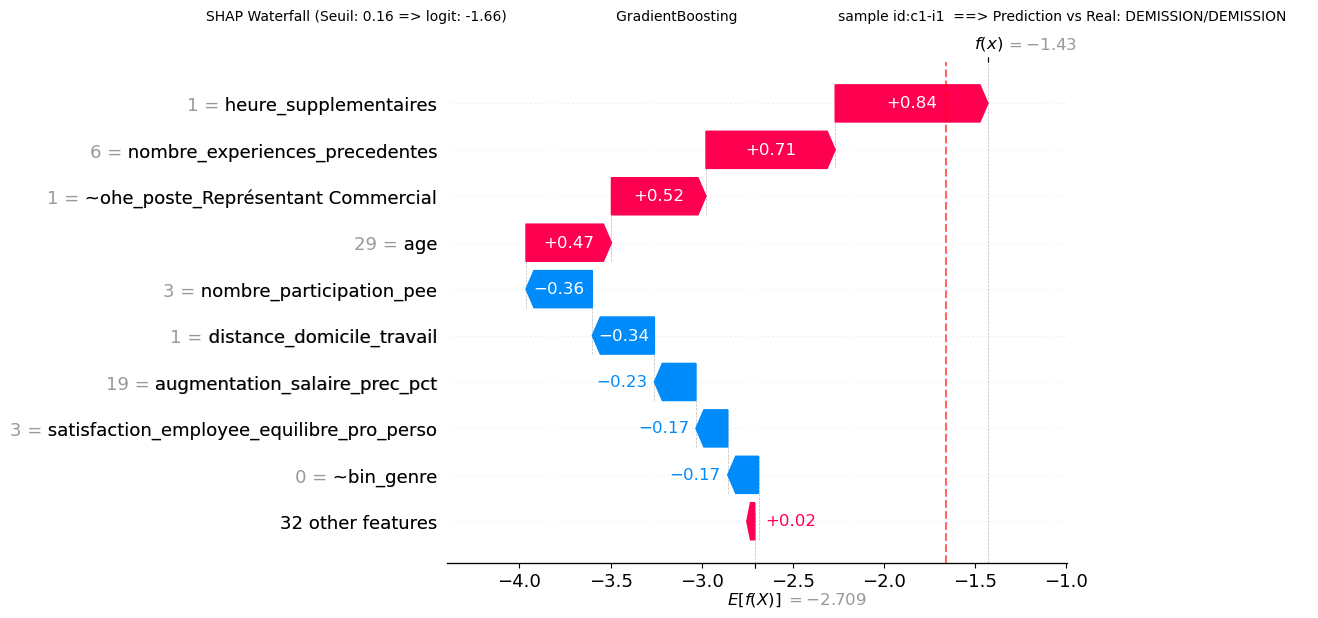

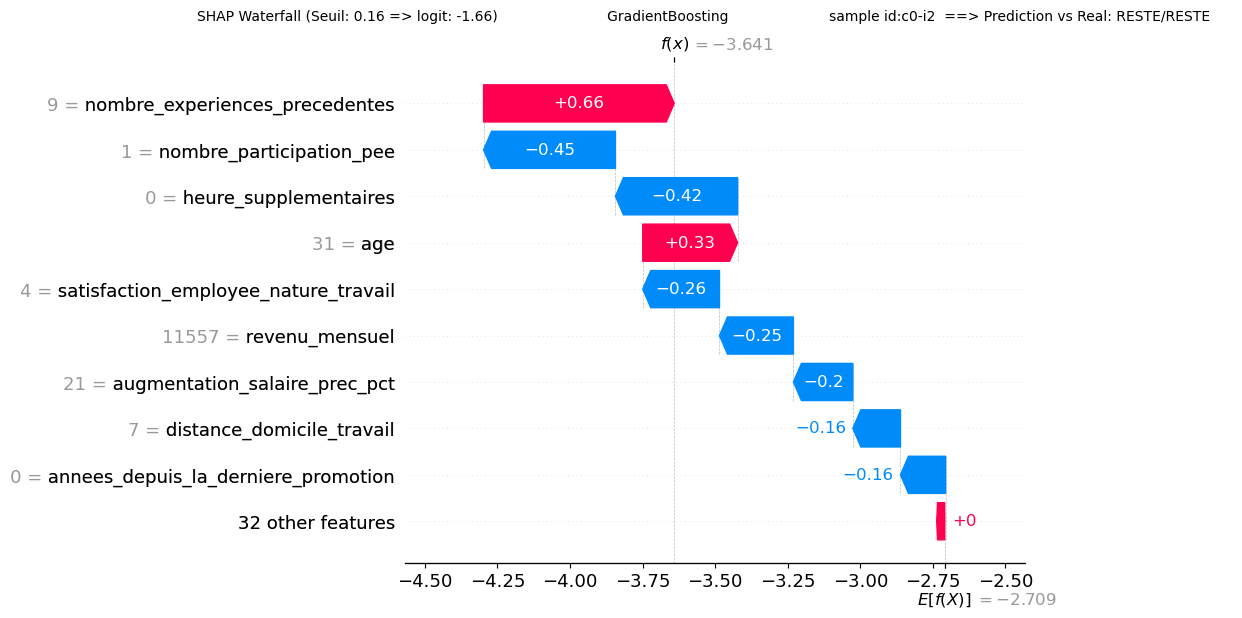

In [119]:
mywaterfall(shap_expl_gb,the_class=1,the_index=0,the_title='GradientBoosting',
            the_seuil=0.16,class1_tag="DEMISSION",class0_tag="RESTE")
mywaterfall(shap_expl_gb,the_class=1,the_index=1,the_title='GradientBoosting',
            the_seuil=0.16,class1_tag="DEMISSION",class0_tag="RESTE")
mywaterfall(shap_expl_gb,the_class=0,the_index=2,the_title='GradientBoosting',
            the_seuil=0.16,class1_tag="DEMISSION",class0_tag="RESTE")

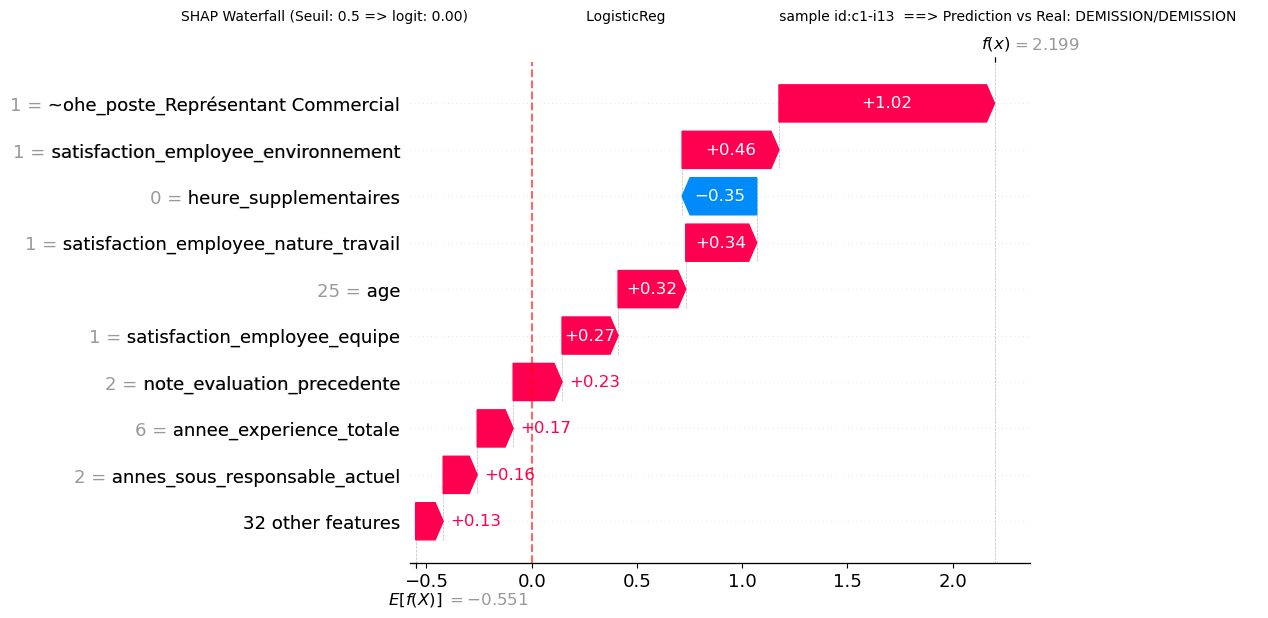

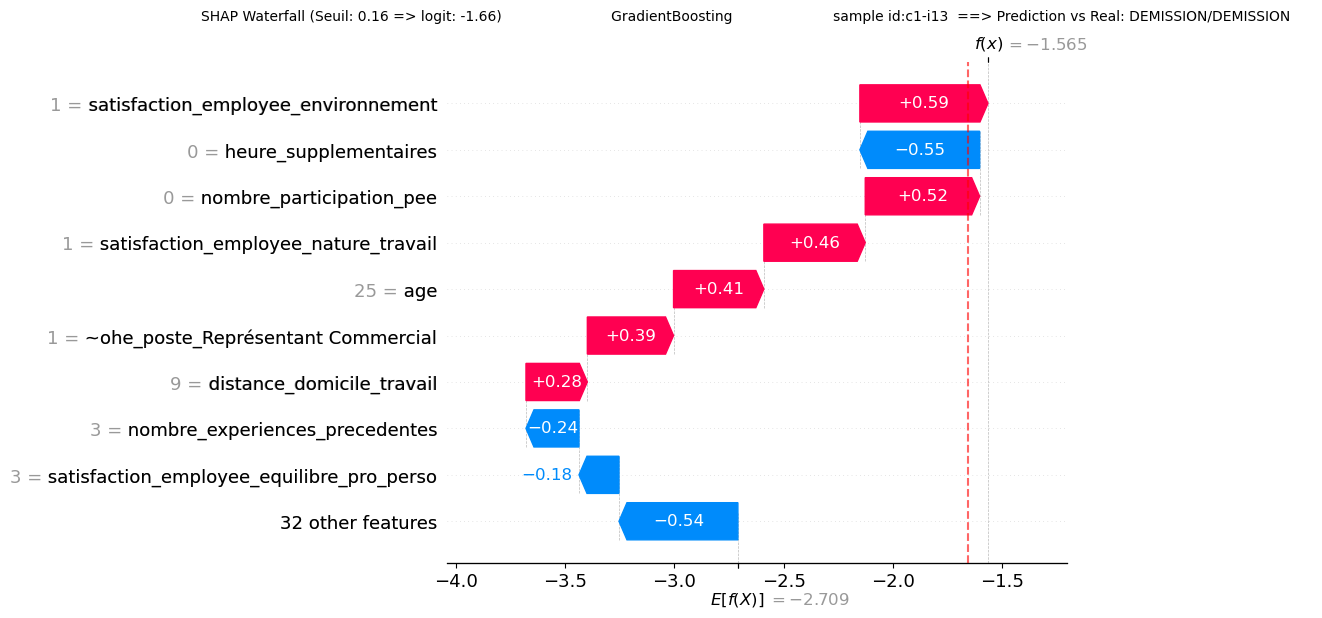

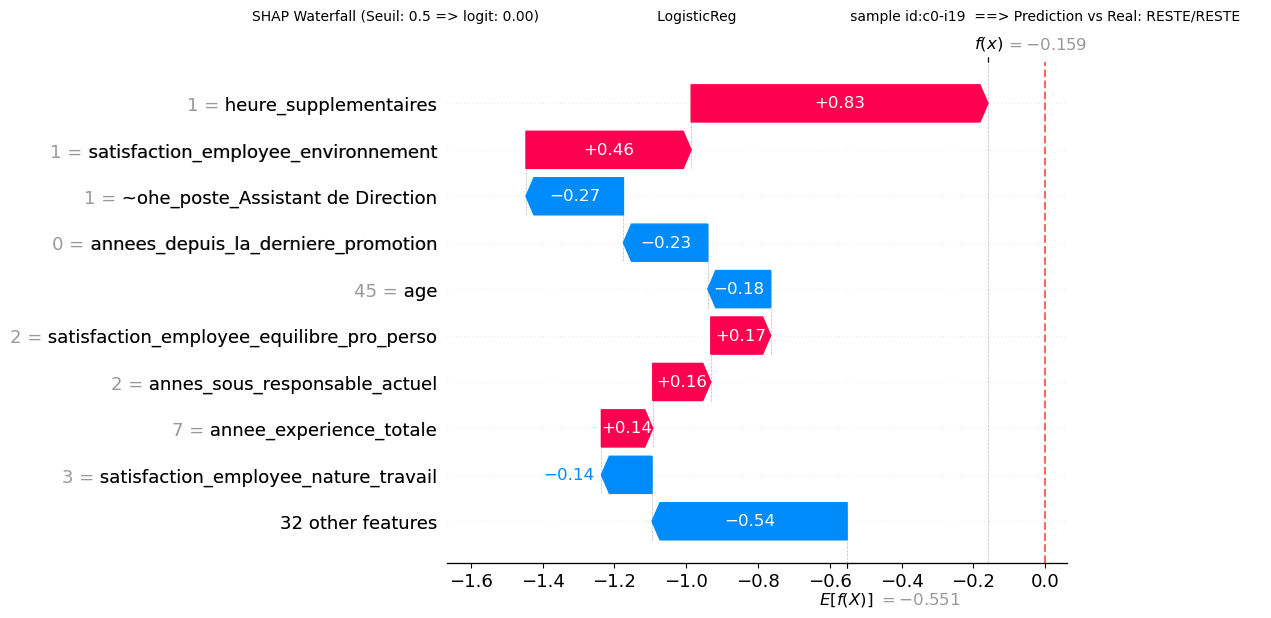

In [120]:
mywaterfall(shap_expl_lr,the_class=1,the_index=13,the_title='LogisticReg',
            the_seuil=0.50,class1_tag="DEMISSION",class0_tag="RESTE")
mywaterfall(shap_expl_gb,the_class=1,the_index=13,the_title='GradientBoosting',
            the_seuil=0.16,class1_tag="DEMISSION",class0_tag="RESTE")
mywaterfall(shap_expl_lr,the_class=0,the_index=19,the_title='LogisticReg',
            the_seuil=0.50,class1_tag="DEMISSION",class0_tag="RESTE")

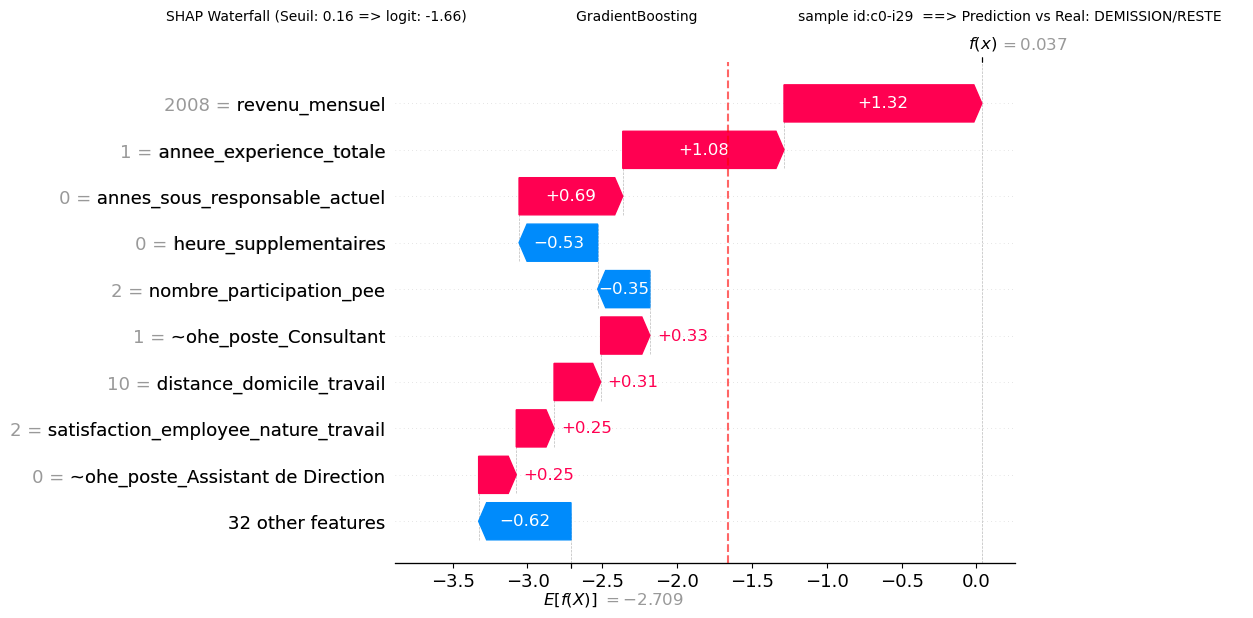

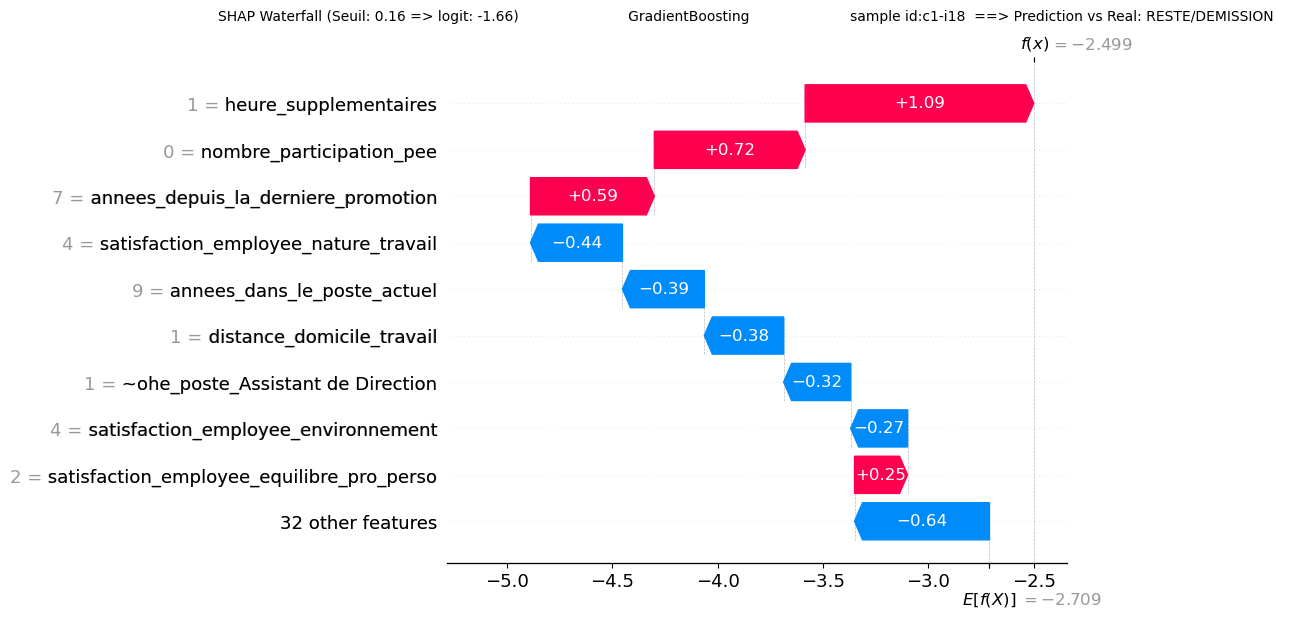

In [137]:
mywaterfall(shap_expl_gb,the_class=0,the_index=29,the_title='GradientBoosting',
            the_seuil=0.16,class1_tag="DEMISSION",class0_tag="RESTE")
mywaterfall(shap_expl_gb,the_class=1,the_index=18,the_title='GradientBoosting',
            the_seuil=0.16,class1_tag="DEMISSION",class0_tag="RESTE")